In this notebook I will try to do a linear reconstruction of a weak phase object.

In [11]:
import sys
sys.path.append("../src/focalseriesrecon")

import numpy as np
from scipy.signal import convolve2d

from utils import *
from optics import *
from specimen import *
from reconstruction import *

Make the phase object:

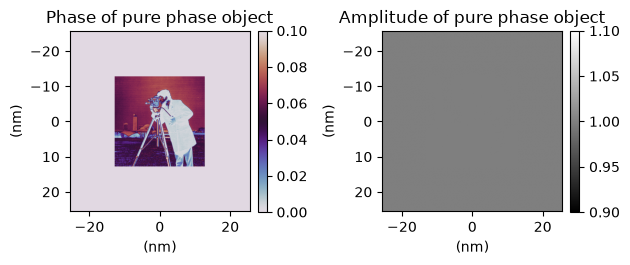

In [12]:
spec = Specimen(phase_source='../images/cameraman512.jpg', phase_strength=0.1, resize_img=512, pixel_size=0.05)

fig, ax1 = plt.subplots(1, 2)
plot_2d(spec.owf, x=spec.x, y=spec.y, mode="phase", title="Phase of pure phase object", xlabel="(nm)", ylabel="(nm)", ax=ax1[0])
plot_2d(spec.owf, x=spec.x, y=spec.y, mode="abs", title="Amplitude of pure phase object", xlabel="(nm)", ylabel="(nm)", ax=ax1[1])
plt.tight_layout()

Generate a focal series and the corresponding filter functions:

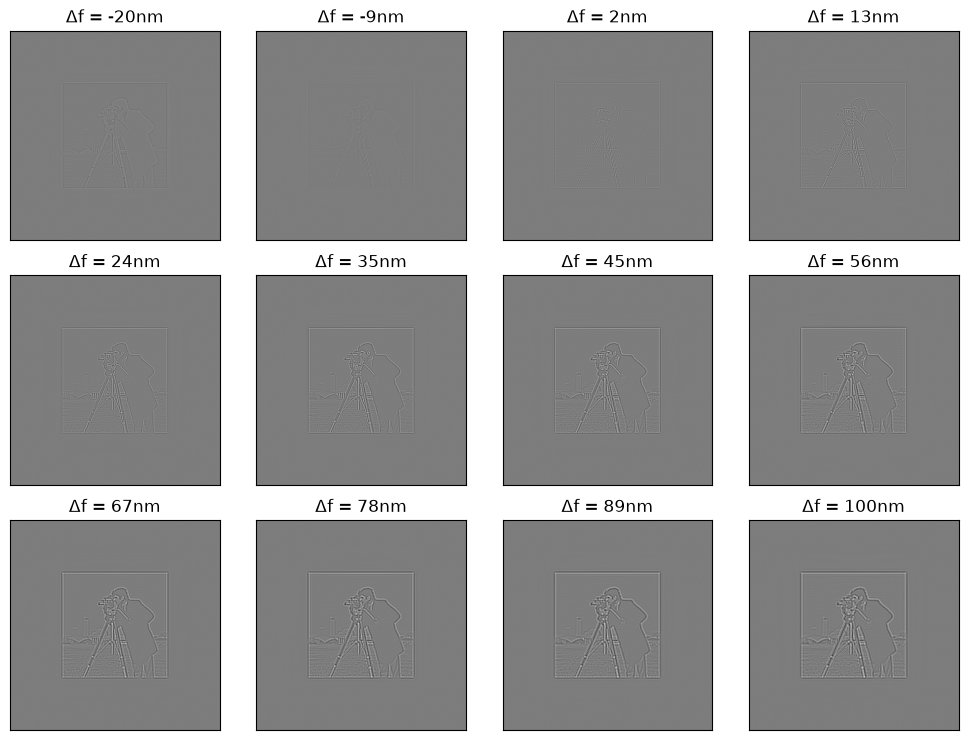

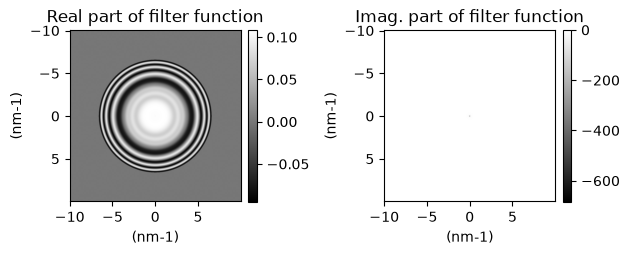

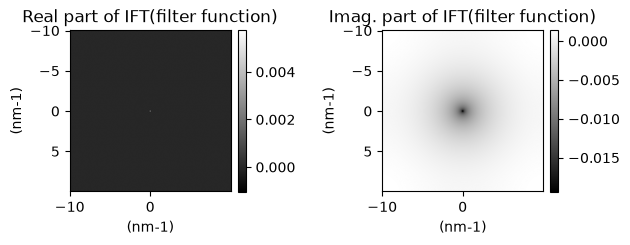

In [17]:
acc_voltage = 300
wavelength = electron_wavelength(acc_voltage)
cs = 1.2e6
aperture_alpha_max = 13
defoci = np.linspace(-20, 100, 12)

focal_series = focal_series_nonlinear(defoci, spec.owf, spec.k_grid, wavelength, cs, aperture_alpha_max)
plot_focal_series(focal_series, defoci)

filter_function_example = filter_function(-15, defoci, spec.k_grid, wavelength, cs, aperture_alpha_max)
filter_function_example_ift = ifft2d(filter_function_example)

fig, ax2 = plt.subplots(1, 2)
plot_2d(filter_function_example, x=spec.kx, y=spec.ky, mode="real", title="Real part of filter function", xlabel="(nm-1)", ylabel="(nm-1)", ax=ax2[0])
plot_2d(filter_function_example, x=spec.kx, y=spec.ky, mode="imag", title="Imag. part of filter function", xlabel="(nm-1)", ylabel="(nm-1)", ax=ax2[1])
plt.tight_layout()

fig, ax3 = plt.subplots(1, 2)
plot_2d(filter_function_example_ift, x=spec.kx, y=spec.ky, mode="real", title="Real part of IFT(filter function)", xlabel="(nm-1)", ylabel="(nm-1)", ax=ax3[0])
plot_2d(filter_function_example_ift, x=spec.kx, y=spec.ky, mode="imag", title="Imag. part of IFT(filter function)", xlabel="(nm-1)", ylabel="(nm-1)", ax=ax3[1])
plt.tight_layout()

We can now apply the filter functions on the defocus series to reconstruct the phase object.

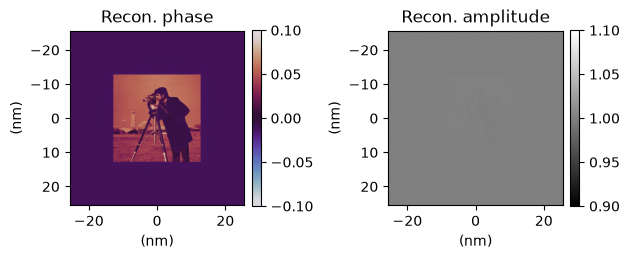

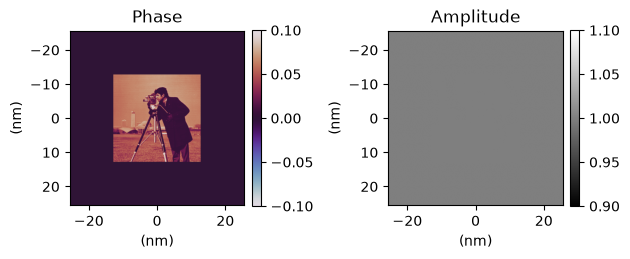

In [ ]:
reconstructed_owf = linear_reconstruction(focal_series, defoci, spec.k_grid, wavelength, cs, aperture_alpha_max)

fig, ax4 = plt.subplots(1, 2)
plot_2d(reconstructed_owf, x=spec.x, y=spec.y, mode="phase", title="Recon. phase", xlabel="(nm)", ylabel="(nm)", vmin=-0.1, vmax=0.1, ax=ax4[0])
plot_2d(reconstructed_owf, x=spec.x, y=spec.y, mode="abs", title="Recon. amplitude", xlabel="(nm)", ylabel="(nm)", vmin=0.9, vmax=1.1, ax=ax4[1])
plt.tight_layout()

fig, ax5 = plt.subplots(1, 2)
plot_2d(spec.owf, x=spec.x, y=spec.y, mode="phase", title="Phase", xlabel="(nm)", ylabel="(nm)", vmin=-0.1, vmax=0.1, ax=ax5[0])
plot_2d(spec.owf, x=spec.x, y=spec.y, mode="abs", title="Amplitude", xlabel="(nm)", ylabel="(nm)", vmin=0.9, vmax=1.1, ax=ax5[1])
plt.tight_layout()